In [1]:

# STEP 1: Install required libraries

!pip install -q pandas numpy requests beautifulsoup4 nltk scikit-learn matplotlib gradio

print("All required libraries are ready!")


All required libraries are ready!


In [2]:

# STEP 2: Import required libraries

import pandas as pd
import numpy as np
import requests
import re
import nltk
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Download English stopwords

nltk.download('stopwords', quiet=True)

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

print("Stopwords loaded successfully!")
print("Example stopwords:", list(sorted(stop_words))[:15])


Stopwords loaded successfully!
Example stopwords: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't"]


In [4]:

# Text preprocessing function

def preprocess_text(text):
    # Convert text to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Keep letters and spaces
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Split text into words
    words = text.split()

    # Remove stopwords and apply stemming
    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    # Return cleaned text
    return ' '.join(words)


# Test the function
sample = "The movie was AMAZING! I really loved it."
cleaned = preprocess_text(sample)

print("Original text:", sample)
print("Processed text:", cleaned)


Original text: The movie was AMAZING! I really loved it.
Processed text: movi amaz realli love


In [5]:

# STEP 3: Collect live news headlines

from bs4 import BeautifulSoup
import requests
import pandas as pd

# BBC News RSS feed
url = "https://feeds.bbci.co.uk/news/rss.xml"

# Request the latest feed
response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=20
)

# Check whether the request succeeded
response.raise_for_status()

# Parse the RSS XML
soup = BeautifulSoup(response.content, "xml")

# Extract news items
news_items = []

for item in soup.find_all("item"):
    title = item.find("title")
    link = item.find("link")
    pub_date = item.find("pubDate")

    if title and title.get_text(strip=True):
        news_items.append({
            "headline": title.get_text(strip=True),
            "link": link.get_text(strip=True) if link else "",
            "published": pub_date.get_text(strip=True) if pub_date else "",
            "source": "BBC News"
        })

# Store the results in a DataFrame
news_df = pd.DataFrame(news_items)

# Remove duplicate headlines
if not news_df.empty:
    news_df = news_df.drop_duplicates(
        subset=["headline"]
    ).reset_index(drop=True)

print("Number of headlines collected:", len(news_df))
display(news_df.head(10))


Number of headlines collected: 28


,headline,link,published,source
0,Met Police says letter with claims about Megha...,https://www.bbc.co.uk/news/articles/c39wz740e0...,"Sat, 24 Oct 2026 12:59:49 GMT",BBC News
1,Plan for Northern Olympics to get £7m in Heale...,https://www.bbc.co.uk/news/articles/cv98z92ekg...,"Sat, 24 Oct 2026 15:45:46 GMT",BBC News
2,Between quick wins and big dreams lies Burnham...,https://www.bbc.co.uk/news/articles/cwq6n09qpy...,"Sat, 24 Oct 2026 11:03:57 GMT",BBC News
3,Mum dies after trying to rescue sons swept awa...,https://www.bbc.co.uk/news/articles/cm86z5n0yv...,"Sat, 24 Oct 2026 09:45:47 GMT",BBC News
4,Infantino tells BBC Sport he is backed by 'vas...,https://www.bbc.co.uk/sport/football/articles/...,"Sat, 24 Oct 2026 10:30:08 GMT",BBC News
5,Strictly's new presenters - after mixed review...,https://www.bbc.co.uk/news/articles/c5zjxp1rjn...,"Fri, 23 Oct 2026 23:15:47 GMT",BBC News
6,Are California voters about to impose 'world's...,https://www.bbc.co.uk/news/articles/ck4g1jg4n9...,"Fri, 23 Oct 2026 23:11:31 GMT",BBC News
7,"Before you crank up the thermostat, try these ...",https://www.bbc.co.uk/news/articles/cqr7yeed1e...,"Fri, 23 Oct 2026 23:50:45 GMT",BBC News
8,The artist dropping her debut album after a bi...,https://www.bbc.co.uk/news/articles/cwj0leg7ng...,"Fri, 23 Oct 2026 23:08:55 GMT",BBC News
9,Ruins of Limoges city hall a symbol of France ...,https://www.bbc.co.uk/news/articles/cxyvrged14...,"Fri, 23 Oct 2026 23:09:16 GMT",BBC News


In [6]:

# Save collected news to a CSV file

if not news_df.empty:
    news_df.to_csv(
        "live_news_headlines.csv",
        index=False,
        encoding="utf-8"
    )

    print("News headlines saved successfully!")
else:
    print("No headlines available to save.")


News headlines saved successfully!


In [7]:

# STEP 4: Download the labeled sentiment dataset

import pandas as pd

base_url = (
    "https://raw.githubusercontent.com/"
    "cardiffnlp/tweeteval/main/datasets/sentiment/"
)

# Load the training, validation, and test data
train_df = pd.read_csv(
    base_url + "train_text.txt",
    sep="\t",
    header=None,
    names=["text"]
)

train_labels = pd.read_csv(
    base_url + "train_labels.txt",
    sep="\t",
    header=None,
    names=["label"]
)

# Attach sentiment labels to the training text
train_df["label"] = train_labels["label"]

# Load validation data
val_df = pd.read_csv(
    base_url + "val_text.txt",
    sep="\t",
    header=None,
    names=["text"]
)

val_labels = pd.read_csv(
    base_url + "val_labels.txt",
    sep="\t",
    header=None,
    names=["label"]
)

val_df["label"] = val_labels["label"]

# Load test data
test_df = pd.read_csv(
    base_url + "test_text.txt",
    sep="\t",
    header=None,
    names=["text"]
)

test_labels = pd.read_csv(
    base_url + "test_labels.txt",
    sep="\t",
    header=None,
    names=["label"]
)

test_df["label"] = test_labels["label"]

# Convert numeric labels to sentiment names
label_map = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

for df in [train_df, val_df, test_df]:
    df["sentiment"] = df["label"].map(label_map)

print("Dataset downloaded successfully!")
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

display(train_df.head(10))


Dataset downloaded successfully!
Training records: 36373
Validation records: 1623
Testing records: 12032


,text,label,sentiment
0,QT @user In the original draft of the 7th book...,2,positive
1,Ben Smith / Smith (concussion) remains out of ...,1,neutral
2,Sorry bout the stream last night I crashed out...,1,neutral
3,Chase Headley's RBI double in the 8th inning o...,1,neutral
4,@user Alciato: Bee will invest 150 million in ...,2,positive
5,@user LIT MY MUM 'Kerry the louboutins I wonde...,2,positive
6,"\"""" SOUL TRAIN\"""" OCT 27 HALLOWEEN SPECIAL ft ...",2,positive
7,So disappointed in wwe summerslam! I want to s...,0,negative
8,"This is the last Sunday w/o football .....,NFL...",2,positive
9,@user @user CENA & AJ sitting in a tree K-I-S-...,1,neutral


In [8]:

# Check the dataset structure

print("Dataset shape:", train_df.shape)
print("\nColumn names:")
print(train_df.columns.tolist())

print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())

print("\nMissing values:")
print(train_df[["text", "label"]].isnull().sum())

print("\nExample records:")
display(train_df.sample(5, random_state=42))


Dataset shape: (36373, 3)

Column names:
['text', 'label', 'sentiment']

Sentiment distribution:
sentiment
neutral     16436
positive    14259
negative     5678
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64

Example records:


,text,label,sentiment
28146,@user I debated it 1st\u002c but now i totally...,1,neutral
21144,Briana has a normal sized bump for how far alo...,2,positive
26494,You missed the part where Saudi Arabia stated ...,1,neutral
12063,@user @user More specifically it tells you tha...,0,negative
19833,@user is there a way to go back and watch some...,2,positive


In [9]:

# Save the training dataset as CSV

train_df.to_csv(
    "sentiment_training_dataset.csv",
    index=False,
    encoding="utf-8"
)

print("Training dataset saved successfully!")


Training dataset saved successfully!


In [10]:

# STEP 5A: Clean the datasets

def clean_dataset(df):
    # Work on a copy to preserve the original data
    df = df.copy()

    # Remove missing text or labels
    df = df.dropna(subset=["text", "label"])

    # Remove empty text
    df["text"] = df["text"].astype(str).str.strip()
    df = df[df["text"] != ""]

    # Remove duplicate text records
    df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

    # Recreate sentiment names from labels
    label_map = {
        0: "negative",
        1: "neutral",
        2: "positive"
    }
    df["sentiment"] = df["label"].map(label_map)

    return df


# Clean each split separately
train_clean = clean_dataset(train_df)
val_clean = clean_dataset(val_df)
test_clean = clean_dataset(test_df)

print("Original training records:", len(train_df))
print("Cleaned training records:", len(train_clean))
print("Cleaned validation records:", len(val_clean))
print("Cleaned testing records:", len(test_clean))

display(train_clean.head())


Original training records: 36373
Cleaned training records: 36353
Cleaned validation records: 1623
Cleaned testing records: 12030


,text,label,sentiment
0,QT @user In the original draft of the 7th book...,2,positive
1,Ben Smith / Smith (concussion) remains out of ...,1,neutral
2,Sorry bout the stream last night I crashed out...,1,neutral
3,Chase Headley's RBI double in the 8th inning o...,1,neutral
4,@user Alciato: Bee will invest 150 million in ...,2,positive


In [11]:

# STEP 5B: Preprocess the text

train_clean["clean_text"] = train_clean["text"].apply(preprocess_text)
val_clean["clean_text"] = val_clean["text"].apply(preprocess_text)
test_clean["clean_text"] = test_clean["text"].apply(preprocess_text)

# Remove text that became empty after preprocessing
train_clean = train_clean[train_clean["clean_text"].str.strip() != ""].reset_index(drop=True)
val_clean = val_clean[val_clean["clean_text"].str.strip() != ""].reset_index(drop=True)
test_clean = test_clean[test_clean["clean_text"].str.strip() != ""].reset_index(drop=True)

print("Text preprocessing completed!")

display(train_clean[["text", "clean_text", "sentiment"]].head(10))


Text preprocessing completed!


,text,clean_text,sentiment
0,QT @user In the original draft of the 7th book...,qt user origin draft th book remu lupin surviv...,positive
1,Ben Smith / Smith (concussion) remains out of ...,ben smith smith concuss remain lineup thursday...,neutral
2,Sorry bout the stream last night I crashed out...,sorri bout stream last night crash tonight sur...,neutral
3,Chase Headley's RBI double in the 8th inning o...,chase headley rbi doubl th inning david price ...,neutral
4,@user Alciato: Bee will invest 150 million in ...,user alciato bee invest million januari anoth ...,positive
5,@user LIT MY MUM 'Kerry the louboutins I wonde...,user lit mum kerri louboutin wonder mani willa...,positive
6,"\"""" SOUL TRAIN\"""" OCT 27 HALLOWEEN SPECIAL ft ...",soul train oct halloween special ft dot finest...,positive
7,So disappointed in wwe summerslam! I want to s...,disappoint wwe summerslam want see john cena w...,negative
8,"This is the last Sunday w/o football .....,NFL...",last sunday w footbal nfl back babi,positive
9,@user @user CENA & AJ sitting in a tree K-I-S-...,user user cena aj sit tree k n g st goe aj job...,neutral


In [12]:

# STEP 5C: Prepare text and labels

X_train_text = train_clean["clean_text"]
y_train = train_clean["label"]

X_val_text = val_clean["clean_text"]
y_val = val_clean["label"]

X_test_text = test_clean["clean_text"]
y_test = test_clean["label"]

print("Training text records:", len(X_train_text))
print("Training labels:", len(y_train))
print("Validation records:", len(X_val_text))
print("Test records:", len(X_test_text))

print("\nLabel meanings:")
print("0 = Negative")
print("1 = Neutral")
print("2 = Positive")


Training text records: 36353
Training labels: 36353
Validation records: 1623
Test records: 12030

Label meanings:
0 = Negative
1 = Neutral
2 = Positive


In [13]:

# Save the cleaned training data

train_clean.to_csv(
    "cleaned_sentiment_training_dataset.csv",
    index=False,
    encoding="utf-8"
)

print("Cleaned training dataset saved successfully!")


Cleaned training dataset saved successfully!


In [14]:

# STEP 6: TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Learn vocabulary from training data and transform it
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)

# Transform validation and test data using the same vocabulary
X_val_tfidf = tfidf_vectorizer.transform(X_val_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("TF-IDF vectorization completed successfully!")

print("\nTraining matrix shape:", X_train_tfidf.shape)
print("Validation matrix shape:", X_val_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

print("\nNumber of learned features:",
      len(tfidf_vectorizer.get_feature_names_out()))


TF-IDF vectorization completed successfully!

Training matrix shape: (36353, 10000)
Validation matrix shape: (1623, 10000)
Testing matrix shape: (12030, 10000)

Number of learned features: 10000


In [15]:

# Inspect the TF-IDF vocabulary

feature_names = tfidf_vectorizer.get_feature_names_out()

print("First 30 features:")
print(feature_names[:30])

# Display a small portion of the training matrix
tfidf_preview = pd.DataFrame.sparse.from_spmatrix(
    X_train_tfidf[:5, :10],
    columns=feature_names[:10]
)

display(tfidf_preview)


First 30 features:
['aa' 'aaliyah' 'aaron' 'aaron rodger' 'aaron samuel' 'ab' 'ab cbn'
 'abandon' 'abbey' 'abbott' 'abc' 'abc sunday' 'abil' 'abl' 'abl see'
 'ablett' 'abort' 'abramovich' 'absenc' 'absolut' 'absolut love' 'abt'
 'abu' 'abu dhabi' 'abus' 'ac' 'ac dc' 'ac milan' 'academi'
 'academi award']


,aa,aaliyah,aaron,aaron rodger,aaron samuel,ab,ab cbn,abandon,abbey,abbott
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


In [16]:

# Save the fitted TF-IDF vectorizer

import joblib

joblib.dump(
    tfidf_vectorizer,
    "tfidf_vectorizer.pkl"
)

print("TF-IDF vectorizer saved successfully!")


TF-IDF vectorizer saved successfully!


In [17]:

# STEP 7A: Train Multinomial Naive Bayes

from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Predict sentiment on validation data
nb_val_predictions = nb_model.predict(X_val_tfidf)

print("Naive Bayes training completed!")


Naive Bayes training completed!


In [18]:

# STEP 7B: Train Logistic Regression

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict sentiment on validation data
lr_val_predictions = lr_model.predict(X_val_tfidf)

print("Logistic Regression training completed!")


Logistic Regression training completed!


In [19]:

# STEP 7C: Compare validation accuracy

from sklearn.metrics import accuracy_score

nb_accuracy = accuracy_score(
    y_val, nb_val_predictions
)

lr_accuracy = accuracy_score(
    y_val, lr_val_predictions
)

print("Naive Bayes Validation Accuracy:",
      round(nb_accuracy * 100, 2), "%")

print("Logistic Regression Validation Accuracy:",
      round(lr_accuracy * 100, 2), "%")


Naive Bayes Validation Accuracy: 43.07 %
Logistic Regression Validation Accuracy: 41.96 %


In [20]:

# STEP 7D: Detailed validation reports

from sklearn.metrics import classification_report

label_names = ["Negative", "Neutral", "Positive"]

print("===== NAIVE BAYES REPORT =====")
print(
    classification_report(
        y_val,
        nb_val_predictions,
        labels=[0, 1, 2],
        target_names=label_names,
        zero_division=0
    )
)

print("\n===== LOGISTIC REGRESSION REPORT =====")
print(
    classification_report(
        y_val,
        lr_val_predictions,
        labels=[0, 1, 2],
        target_names=label_names,
        zero_division=0
    )
)


===== NAIVE BAYES REPORT =====
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00       258
     Neutral       0.44      0.72      0.55       713
    Positive       0.40      0.29      0.34       652

    accuracy                           0.43      1623
   macro avg       0.28      0.34      0.29      1623
weighted avg       0.36      0.43      0.38      1623


===== LOGISTIC REGRESSION REPORT =====
              precision    recall  f1-score   support

    Negative       0.18      0.01      0.02       258
     Neutral       0.44      0.59      0.50       713
    Positive       0.40      0.40      0.40       652

    accuracy                           0.42      1623
   macro avg       0.34      0.33      0.31      1623
weighted avg       0.38      0.42      0.38      1623



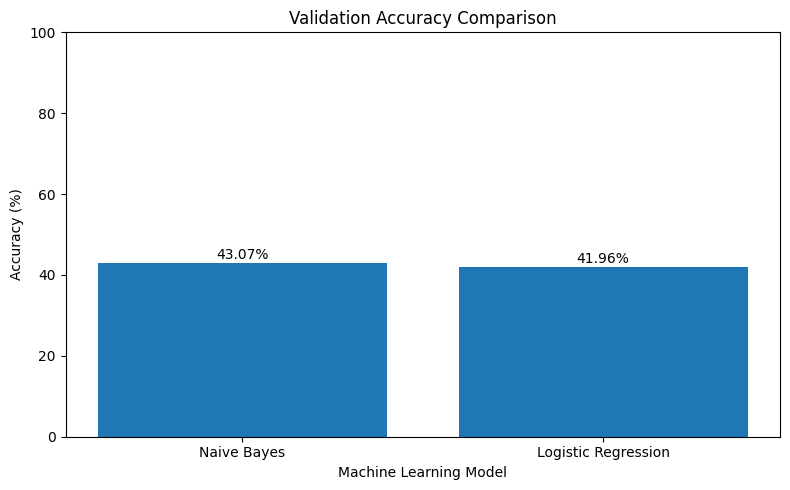

In [21]:

# STEP 7E: Visualize model accuracy

model_names = ["Naive Bayes", "Logistic Regression"]
accuracies = [nb_accuracy * 100, lr_accuracy * 100]

plt.figure(figsize=(8, 5))

bars = plt.bar(model_names, accuracies)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [22]:

# STEP 7F: Save the trained models

import joblib

joblib.dump(nb_model, "naive_bayes_model.pkl")
joblib.dump(lr_model, "logistic_regression_model.pkl")

print("Both trained models saved successfully!")


Both trained models saved successfully!


In [23]:

# Generate predictions on the held-out test dataset

nb_test_predictions = nb_model.predict(X_test_tfidf)
lr_test_predictions = lr_model.predict(X_test_tfidf)

print("Test predictions completed successfully!")
print("Naive Bayes predictions:", len(nb_test_predictions))
print("Logistic Regression predictions:", len(lr_test_predictions))


Test predictions completed successfully!
Naive Bayes predictions: 12030
Logistic Regression predictions: 12030


In [24]:

from sklearn.metrics import accuracy_score

nb_test_accuracy = accuracy_score(y_test, nb_test_predictions)
lr_test_accuracy = accuracy_score(y_test, lr_test_predictions)

print("===== TEST ACCURACY =====")
print("Naive Bayes:", round(nb_test_accuracy * 100, 2), "%")
print("Logistic Regression:", round(lr_test_accuracy * 100, 2), "%")


===== TEST ACCURACY =====
Naive Bayes: 40.69 %
Logistic Regression: 36.56 %


In [25]:

from sklearn.metrics import classification_report

label_names = ["Negative", "Neutral", "Positive"]

print("===== NAIVE BAYES: TEST REPORT =====")
print(classification_report(
    y_test,
    nb_test_predictions,
    labels=[0, 1, 2],
    target_names=label_names,
    zero_division=0
))

print("\n===== LOGISTIC REGRESSION: TEST REPORT =====")
print(classification_report(
    y_test,
    lr_test_predictions,
    labels=[0, 1, 2],
    target_names=label_names,
    zero_division=0
))


===== NAIVE BAYES: TEST REPORT =====
              precision    recall  f1-score   support

    Negative       1.00      0.00      0.00      3902
     Neutral       0.49      0.73      0.59      5802
    Positive       0.19      0.27      0.23      2326

    accuracy                           0.41     12030
   macro avg       0.56      0.34      0.27     12030
weighted avg       0.60      0.41      0.33     12030


===== LOGISTIC REGRESSION: TEST REPORT =====
              precision    recall  f1-score   support

    Negative       0.35      0.01      0.02      3902
     Neutral       0.49      0.59      0.53      5802
    Positive       0.19      0.40      0.26      2326

    accuracy                           0.37     12030
   macro avg       0.34      0.33      0.27     12030
weighted avg       0.38      0.37      0.31     12030



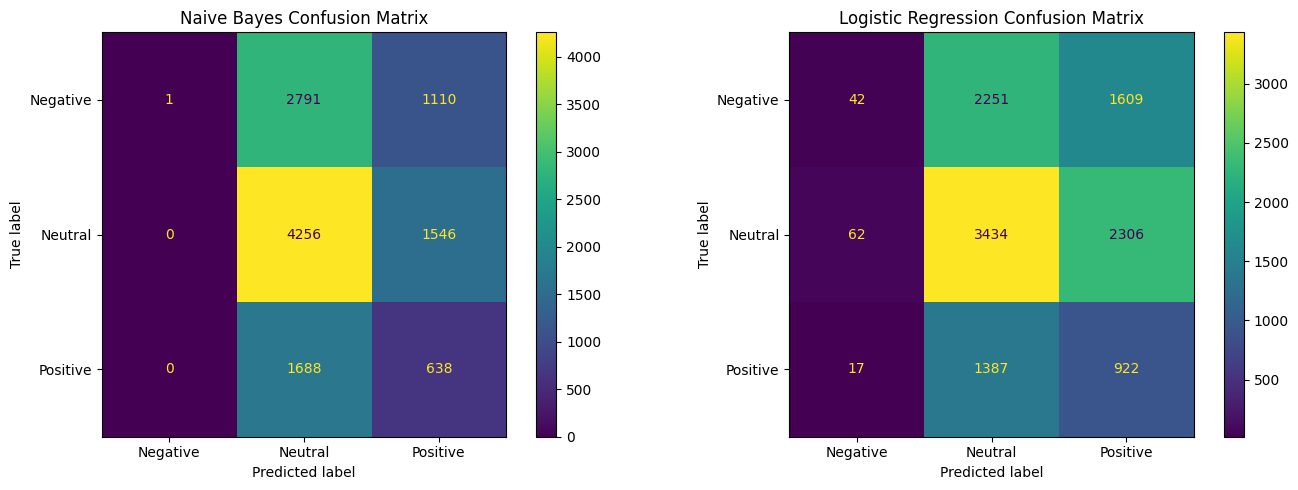

In [26]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = [0, 1, 2]
label_names = ["Negative", "Neutral", "Positive"]

nb_cm = confusion_matrix(y_test, nb_test_predictions, labels=labels)
lr_cm = confusion_matrix(y_test, lr_test_predictions, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(
    confusion_matrix=nb_cm,
    display_labels=label_names
).plot(ax=axes[0], values_format="d")

axes[0].set_title("Naive Bayes Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=label_names
).plot(ax=axes[1], values_format="d")

axes[1].set_title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()


,Model,Test Accuracy (%),Weighted F1 (%)
0,Naive Bayes,40.69,32.65
1,Logistic Regression,36.56,31.38


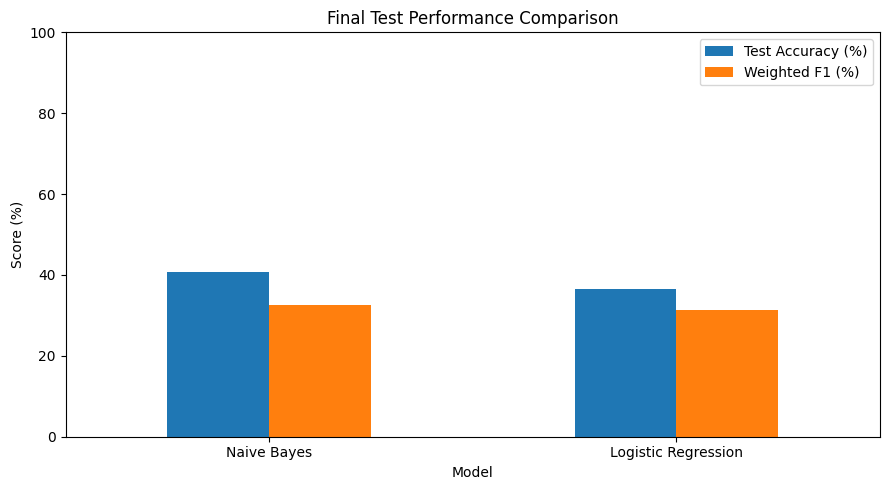

In [27]:

from sklearn.metrics import f1_score
import pandas as pd
import matplotlib.pyplot as plt

nb_weighted_f1 = f1_score(
    y_test, nb_test_predictions, average="weighted"
)
lr_weighted_f1 = f1_score(
    y_test, lr_test_predictions, average="weighted"
)

results_df = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Test Accuracy (%)": [
        nb_test_accuracy * 100,
        lr_test_accuracy * 100
    ],
    "Weighted F1 (%)": [
        nb_weighted_f1 * 100,
        lr_weighted_f1 * 100
    ]
})

display(results_df.round(2))

results_df.set_index("Model")[
    ["Test Accuracy (%)", "Weighted F1 (%)"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Final Test Performance Comparison")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [28]:

results_df.to_csv("final_test_model_comparison.csv", index=False)
print("Final test comparison saved successfully!")


Final test comparison saved successfully!


In [29]:

# Check that live news headlines are available

print("Total live headlines:", len(news_df))
display(news_df[["headline", "source"]].head())


Total live headlines: 28


,headline,source
0,Met Police says letter with claims about Megha...,BBC News
1,Plan for Northern Olympics to get £7m in Heale...,BBC News
2,Between quick wins and big dreams lies Burnham...,BBC News
3,Mum dies after trying to rescue sons swept awa...,BBC News
4,Infantino tells BBC Sport he is backed by 'vas...,BBC News


In [30]:

# Remove missing and duplicate headlines
live_df = news_df.dropna(subset=["headline"]).copy()
live_df = live_df.drop_duplicates(subset=["headline"]).reset_index(drop=True)

# Clean the headlines using the same preprocessing function
live_df["clean_text"] = live_df["headline"].apply(preprocess_text)

# Remove empty cleaned headlines
live_df = live_df[live_df["clean_text"].str.strip() != ""].reset_index(drop=True)

# Convert headlines into TF-IDF features
live_tfidf = tfidf_vectorizer.transform(live_df["clean_text"])

# Predict sentiment using the selected model
live_predictions = nb_model.predict(live_tfidf)

# Convert numeric labels into readable sentiment names
label_map = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

live_df["predicted_sentiment"] = [
    label_map[int(label)] for label in live_predictions
]

print("Live sentiment prediction completed!")
display(live_df[["headline", "predicted_sentiment"]].head(15))


Live sentiment prediction completed!


,headline,predicted_sentiment
0,Met Police says letter with claims about Megha...,Neutral
1,Plan for Northern Olympics to get £7m in Heale...,Neutral
2,Between quick wins and big dreams lies Burnham...,Positive
3,Mum dies after trying to rescue sons swept awa...,Neutral
4,Infantino tells BBC Sport he is backed by 'vas...,Neutral
5,Strictly's new presenters - after mixed review...,Positive
6,Are California voters about to impose 'world's...,Neutral
7,"Before you crank up the thermostat, try these ...",Neutral
8,The artist dropping her debut album after a bi...,Neutral
9,Ruins of Limoges city hall a symbol of France ...,Positive


Live Sentiment Counts:
predicted_sentiment
Neutral     19
Positive     9
Name: count, dtype: int64


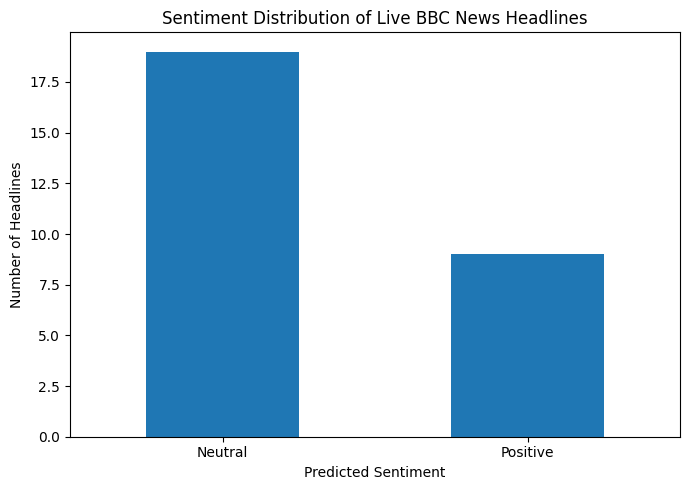

In [31]:

import matplotlib.pyplot as plt

sentiment_counts = live_df["predicted_sentiment"].value_counts()

print("Live Sentiment Counts:")
print(sentiment_counts)

sentiment_counts.plot(kind="bar", figsize=(7, 5))

plt.title("Sentiment Distribution of Live BBC News Headlines")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Headlines")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [32]:

live_df.to_csv("live_news_sentiment_predictions.csv", index=False)
print("Live predictions saved successfully!")


Live predictions saved successfully!


In [33]:

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

label_map = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

# Predict sentiment for text entered by the user
def predict_sentiment(text):
    if not text or not text.strip():
        return "Please enter some text."

    cleaned_text = preprocess_text(text)

    if not cleaned_text.strip():
        return "Please enter meaningful English text."

    text_tfidf = tfidf_vectorizer.transform([cleaned_text])
    prediction = int(nb_model.predict(text_tfidf)[0])

    return "Predicted Sentiment: " + label_map[prediction]


# Display the distribution of live news predictions
def create_sentiment_chart():
    counts = (
        live_df["predicted_sentiment"]
        .value_counts()
        .reindex(["Negative", "Neutral", "Positive"], fill_value=0)
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    counts.plot(kind="bar", ax=ax)
    ax.set_title("Live BBC News Sentiment Distribution")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Number of Headlines")
    ax.tick_params(axis="x", rotation=0)
    fig.tight_layout()

    return fig


with gr.Blocks(title="Real-Time Sentiment Analysis") as demo:
    gr.Markdown("# Real-Time Sentiment Analysis System")
    gr.Markdown(
        "Analyze text sentiment using Naive Bayes "
        "and view predictions from scraped BBC news headlines."
    )

    with gr.Tab("Text Sentiment Prediction"):
        input_text = gr.Textbox(
            label="Enter text",
            placeholder="Example: I am happy with this result."
        )
        predict_button = gr.Button("Predict Sentiment")
        output_text = gr.Textbox(label="Prediction")

        predict_button.click(
            fn=predict_sentiment,
            inputs=input_text,
            outputs=output_text
        )

    with gr.Tab("Live News Dashboard"):
        chart_output = gr.Plot(label="Sentiment Distribution")
        refresh_button = gr.Button("Refresh Chart")
        refresh_button.click(
            fn=create_sentiment_chart,
            inputs=None,
            outputs=chart_output
        )

        gr.Markdown(
            "The chart uses the latest headlines already stored "
            "in the live_df DataFrame."
        )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a30303327d52f23fbb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
